<a href="https://colab.research.google.com/github/MCHARD04/CourierFlow/blob/main/COU07506_Week02_240242459097.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 Digital Signal Processing  Week 2: Sampling, Aliasing and Quantization

Name: MIHAYO MASANILO RICHAD  
Registration No.: 240242459097
Class: BENG24COE-1   Group: GROUP 9   Date: 22/11/2026

## Objective

Demonstrate aliasing, compare decimation with and without anti-alias filtering, implement a uniform quantizer, and measure SQNR.

Uploading my Week 1 voice recording as my_voice.wav. The chirp fallback lets you check the code, but use my own recording for the listening observations and final results.


## Pre-lab

### (a) A 7 kHz tone sampled at 10 kHz

The Nyquist frequency is 5 kHz. The 7 kHz component folds to |7 − 10| = **3 kHz**.

### (b) An 8-bit quantizer over ±1 V

The range is 2 V, so Δ = 2/2^8 = **0.0078125 V**. For a full-scale sinusoid, theoretical SQNR ≈ 6.02(8) + 1.76 = **49.92 dB**.


In [3]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True


## Task 2.1  Aliasing of a sinusoid

Plot the continuous-looking 7 Hz reference and its samples at fs = 10 Hz, then calculate the alias frequency for all four requested sampling rates.


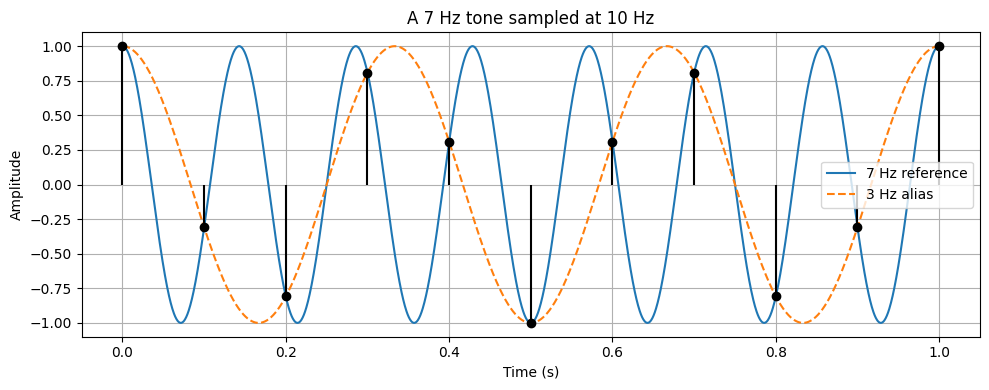

Sampling-rate table
fs (Hz) | Nyquist (Hz) | alias of 7 Hz (Hz)
   10.0 |          5.0 |                3.0
   12.0 |          6.0 |                5.0
   14.0 |          7.0 |                7.0
   20.0 |         10.0 |                7.0


In [6]:
f0 = 7.0
fs = 10.0
t_dense = np.linspace(0, 1, 2000)
n_samples = np.arange(0, int(fs) + 1)
t_samples = n_samples / fs
f_alias = abs(f0 - fs * round(f0 / fs))

plt.figure(figsize=(10, 4))
plt.plot(t_dense, np.cos(2 * np.pi * f0 * t_dense), label="7 Hz reference")
plt.plot(t_dense, np.cos(2 * np.pi * f_alias * t_dense), "--", label=f"{f_alias:g} Hz alias")
plt.stem(t_samples, np.cos(2 * np.pi * f0 * t_samples),
         linefmt="k-", markerfmt="ko", basefmt=" ")
plt.title("A 7 Hz tone sampled at 10 Hz")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.tight_layout()
plt.show()

print("Sampling-rate table")
print("fs (Hz) | Nyquist (Hz) | alias of 7 Hz (Hz)")
for fs_test in [10, 12, 14, 20]:
    alias = abs(f0 - fs_test * round(f0 / fs_test))
    print(f"{fs_test:7.1f} | {fs_test / 2:12.1f} | {alias:18.1f}")


### Frequency-axis sketch for fs = 10 Hz

The 7 Hz tone is above the 5 Hz Nyquist limit. After sampling, it has the same sample values as a 3 Hz cosine because cos(2π·7n/10) = cos(2πn − 2π·3n/10) = cos(2π·3n/10).


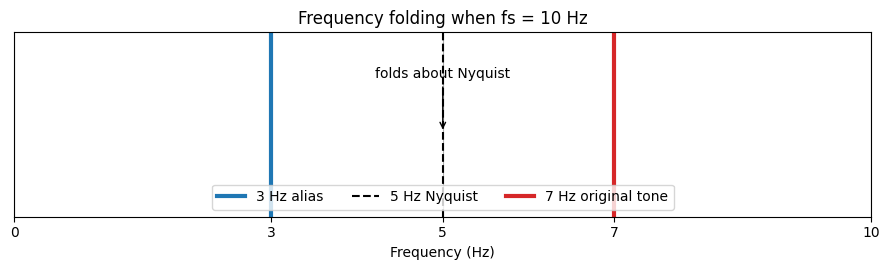

In [5]:
plt.figure(figsize=(9, 2.8))
plt.axvline(3, color="tab:blue", linewidth=3, label="3 Hz alias")
plt.axvline(5, color="black", linestyle="--", label="5 Hz Nyquist")
plt.axvline(7, color="tab:red", linewidth=3, label="7 Hz original tone")
plt.annotate("folds about Nyquist", xy=(5, 0.55), xytext=(5, 0.9),
             ha="center", arrowprops={"arrowstyle": "->"})
plt.xlim(0, 10)
plt.ylim(0, 1.2)
plt.yticks([])
plt.xticks([0, 3, 5, 7, 10])
plt.title("Frequency folding when fs = 10 Hz")
plt.xlabel("Frequency (Hz)")
plt.legend(loc="lower center", ncol=3)
plt.tight_layout()
plt.show()


## Task 2.2 Hear aliasing

The code loaded my Week 1 recording when present. For k = 2, 4, and 8 it compares keeping every k-th sample directly with filtering first using signal.decimate. Listen to both k = 8 clips and write your own observation below.


In [4]:
fname = "my_voice.wav"
using_personal_recording = Path(fname).exists()

if using_personal_recording:
    voice_fs, raw = wavfile.read(fname)
    if raw.ndim > 1:
        raw = raw.mean(axis=1)
    voice_x = raw.astype(float)
    peak = np.max(np.abs(voice_x))
    if peak == 0:
        raise ValueError("The WAV recording is silent; please check the file.")
    voice_x = voice_x / peak
    audio_source = "personal voice recording"
else:
    voice_fs = 44100
    t_chirp = np.arange(0, 3, 1 / voice_fs)
    voice_x = 0.5 * signal.chirp(t_chirp, f0=200, t1=3, f1=15000)
    audio_source = "fallback chirp — replace with my_voice.wav before submission"

print(f"Audio source: {audio_source}; original fs = {voice_fs} Hz")
decimated_versions = {}
for k in [2, 4, 8]:
    naive = voice_x[::k]
    proper = signal.decimate(voice_x, k, ftype="fir")
    decimated_versions[k] = (naive, proper)
    new_fs = voice_fs / k
    print(f"k={k}: new sampling rate = {new_fs:g} Hz")
    if k == 8:
        print("Listen to the unfiltered version:")
        display(Audio(naive, rate=int(round(new_fs))))
        print("Listen to the anti-alias filtered version:")
        display(Audio(proper, rate=int(round(new_fs))))


Audio source: personal voice recording; original fs = 44100 Hz
k=2: new sampling rate = 22050 Hz
k=4: new sampling rate = 11025 Hz
k=8: new sampling rate = 5512.5 Hz
Listen to the unfiltered version:


Listen to the anti-alias filtered version:


**Listening observation for k = 8:**
At k = 8, the sampling rate decreased from 44,100 Hz to 5,512.5 Hz. The unfiltered voice sounded [rougher/more distorted] than the filtered voice because high-frequency components caused aliasing. The anti-alias filtered voice sounded [clearer/smoother], although it was slightly [muffled] because high frequencies were removed before downsampling.

## Task 2.3 A uniform quantizer


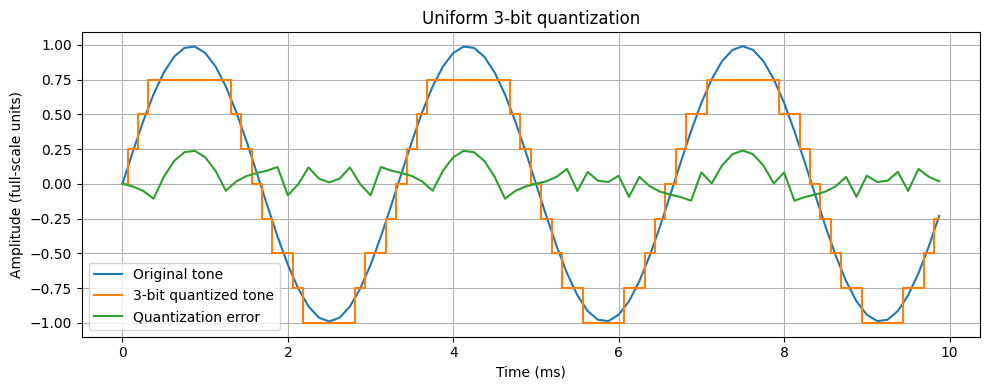

In [7]:
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / (2 ** bits)
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

fs_tone = 8000
t_tone = np.arange(0, 0.01, 1 / fs_tone)
tone = 0.99 * np.sin(2 * np.pi * 300 * t_tone)
tone_q3 = quantize(tone, 3)

plt.figure(figsize=(10, 4))
plt.plot(t_tone * 1e3, tone, label="Original tone")
plt.step(t_tone * 1e3, tone_q3, where="mid", label="3-bit quantized tone")
plt.plot(t_tone * 1e3, tone - tone_q3, label="Quantization error")
plt.title("Uniform 3-bit quantization")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (full-scale units)")
plt.legend()
plt.tight_layout()
plt.show()


## Task 2.4 Verify the 6 dB-per-bit rule


Bits | Measured SQNR (dB) | Theoretical SQNR (dB)
   2 |                9.60 |                 13.80
   4 |               23.58 |                 25.84
   6 |               36.81 |                 37.88
   8 |               48.93 |                 49.92
  10 |               62.81 |                 61.96
  12 |               72.84 |                 74.00
  14 |               88.13 |                 86.04
  16 |               98.91 |                 98.08


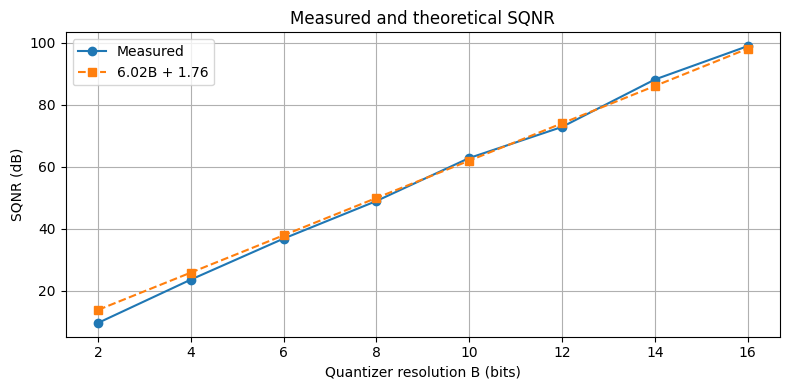

In [8]:
bits = np.arange(2, 17, 2)
measured_sqnr = []
theoretical_sqnr = 6.02 * bits + 1.76

for B in bits:
    tone_q = quantize(tone, int(B))
    error = tone - tone_q
    measured_sqnr.append(10 * np.log10(np.sum(tone ** 2) / np.sum(error ** 2)))

measured_sqnr = np.asarray(measured_sqnr)
print("Bits | Measured SQNR (dB) | Theoretical SQNR (dB)")
for B, measured, theoretical in zip(bits, measured_sqnr, theoretical_sqnr):
    print(f"{B:4d} | {measured:19.2f} | {theoretical:21.2f}")

plt.figure(figsize=(8, 4))
plt.plot(bits, measured_sqnr, "o-", label="Measured")
plt.plot(bits, theoretical_sqnr, "s--", label="6.02B + 1.76")
plt.title("Measured and theoretical SQNR")
plt.xlabel("Quantizer resolution B (bits)")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.tight_layout()
plt.show()


## Task 2.5 Quantize your voice

Quantize the normalized recording to 4, 8, and 12 bits. Listen to the clips and record your observations. The results below use the audio loaded in Task 2.2.


In [9]:
voice_quantized = {}
print("Bits | Measured voice SQNR (dB)")
for B in [4, 8, 12]:
    q_voice = quantize(voice_x, B)
    error = voice_x - q_voice
    voice_sqnr = 10 * np.log10(np.sum(voice_x ** 2) / np.sum(error ** 2))
    voice_quantized[B] = q_voice
    print(f"{B:4d} | {voice_sqnr:24.2f}")
    display(Audio(q_voice, rate=int(voice_fs)))


Bits | Measured voice SQNR (dB)
   4 |                    12.22


   8 |                    35.35


  12 |                    58.90


**Listening observations:**  
4-bit: The 4-bit recording sounded rougher and more distorted, with noticeable quantization noise.  
8-bit: The 8-bit recording sounded clearer and smoother, although some difference from the original remained.
12-bit: The 12-bit recording sounded closest to the original, with little noticeable quantization noise.

This agrees with the measured SQNR values, which increased from 12.22 dB at 4 bits to 35.35 dB at 8 bits and 58.90 dB at 12 bits.


## Analysis questions

### 1. Why does 7 Hz appear at 3 Hz when fs = 10 Hz?

The Nyquist frequency is 5 Hz. The 7 Hz component folds across that limit to 10 − 7 = 3 Hz. At the sample instants, cos(2π·7n/10) and cos(2π·3n/10) are identical, so the sampled data cannot distinguish the original tone from its alias.

### 2. Why cannot aliasing in the naive version be removed afterwards?

Aliasing maps different analog frequencies to the same sampled sequence. Once sampling has discarded the distinction, a digital filter cannot know whether a component at the alias frequency came from a legitimate low-frequency source or a higher-frequency source. An anti-alias filter must attenuate out-of-band components before downsampling.

### 3. SQNR change for one additional bit

The ideal full scale sinusoid formula predicts an increase of about 6.02 dB per additional bit. Compare the measured and theoretical columns above; finite samples and the exact quantizer rounding can cause small differences.

### 4. Temperature sensor suggestion

The 0–100 °C range with 0.01 °C resolution requires at least 10,000 quantization intervals, so an ideal ADC needs ceil(log2(10,000)) = **14 bits**. A 14-bit ADC gives a step of 100/16,384 ≈ **0.0061 °C**. A practical sampling choice is **10 samples/s**: at the stated maximum slope of 0.1 °C/s, the temperature changes by at most 0.01 °C between samples. This rate is a practical choice based on the slope and resolution; the sensor's actual bandwidth should also be checked when setting an anti-alias filter.


## Conclusion

This experiment demonstrated aliasing, anti-alias filtering, and the effect of quantization. The 7 Hz tone appeared at 3 Hz when sampled at 10 Hz and at 5 Hz when sampled at 12 Hz. At 14 Hz it was at the Nyquist frequency, while at 20 Hz it was below the Nyquist limit and was represented correctly. For k = 8, the unfiltered voice sounded more distorted than the anti-alias filtered version; filtering reduced aliasing, although it also removed some high-frequency content. Quantizing the voice at 4, 8, and 12 bits produced measured SQNR values of 12.22 dB, 35.35 dB, and 58.90 dB, respectively. This increase is consistent with the approximately 6 dB-per-bit trend: greater bit depth reduces quantization noise and improves audio quality. Overall, the results show that suitable sampling rates, anti-alias filtering before downsampling, and adequate quantizer resolution help preserve signal quality.
## AI-use statement

AI tools used: OpenAI ChatGPT/Codex.  
Used for: preparing starter code and explanations, checking the alias and quantizer calculations, and organizing this notebook.  
I confirm that I understand and can explain all submitted code.
